In [1]:
import json
from typing import Dict, List, Tuple, Optional, Any
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt  # ← AJOUT pour graphiques
from pathlib import Path  # ← AJOUT pour chemins
import shutil  # ← AJOUT pour renommer fichiers
import re
import sys
import traceback
import math
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image as RLImage, PageBreak
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import cm
import os
try:
    from langchain_ollama import ChatOllama
except Exception:
    ChatOllama = None


# Import du client Ollama et du wrapper LangChain avec gestion d'erreur
try:
    import ollama
    OLLAMA_AVAILABLE = True
    print("✅ Module ollama importé avec succès")
except ImportError as e:
    OLLAMA_AVAILABLE = False
    print(f"❌ Erreur d'import ollama (ImportError): {e}")
except Exception as e:
    OLLAMA_AVAILABLE = False
    print(f"❌ Erreur d'import ollama (Exception): {e}")

try:
    LANGCHAIN_AVAILABLE = ChatOllama is not None
    if LANGCHAIN_AVAILABLE:
        print("✅ LangChain Ollama disponible")
    else:
        print("❌ LangChain indisponible: package langchain_ollama manquant")
except Exception as e:
    LANGCHAIN_AVAILABLE = False
    print(f"❌ LangChain indisponible: {e}")


# --- 🛠️ Configuration Globale ---
DATA_FILE = "adult.data" 
LLM_MODEL = "llama3.1" 
P_RULE_THRESHOLD = 0.8 
MAX_TOTAL_EPOCHS = 1500  # Augmenté de 800 à 1500 pour convergence complète
EPOCHS_PER_STEP = 50
INITIAL_EPOCHS = 10
MEMORY_FILE = "orchestrator_memory.json" 

# Stratégie d'ajustement du Lambda
# MODIFICATION: Réduction du learning rate pour éviter les oscillations
LAMBDA_LEARNING_RATE = 2.5  # Réduit de 5.0 à 2.5 pour convergence stable
LAMBDA_MAX = 20.0

# Option pour utiliser le LLM pour identifier les attributs sensibles
# Si False, utilisera directement 'race' et 'sex' pour garantir reproductibilité exacte
USE_LLM_FOR_SENSITIVE_ATTRIBUTES = True  # True = Utilise Ollama

# Définition des colonnes pour le dataset Adult (non modifiées)
ADULT_COLUMN_NAMES = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num', 
    'marital-status', 'occupation', 'relationship', 'race', 'sex', 
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 
    'income' 
]
TARGET_COLUMN = 'income'
COLUMNS_TO_IGNORE = ['fnlwgt', 'education-num']
DATASET_CONTEXT = """
Ce jeu de données est une extraction de la base de données de recensement des États-Unis. 
La tâche de prédiction consiste à déterminer si une personne gagne plus de 50 000 $ par an. 
Il contient des informations démographiques (âge, race, sexe, pays d'origine) et socio-économiques 
(classe de travail, éducation, profession, heures travaillées).
"""
BINARIZATION_RULES = {
    'sex': {'positive_value': 'Male'}, 
    'race': {'positive_value': 'White'} 
}


# ======================================================================
## STRUCTURES DES RÉSEAUX DE NEURONES (Non modifiées)
# ======================================================================

class Classifier(nn.Module):
    """Réseau de neurones pour la classification binaire."""
    def __init__(self, n_features: int, n_hidden: int = 32, p_dropout: float = 0.2):
        super(Classifier, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(n_features, n_hidden), nn.ReLU(), nn.Dropout(p_dropout),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(), nn.Dropout(p_dropout),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(), nn.Dropout(p_dropout),
            nn.Linear(n_hidden, 1),
        )
    def forward(self, x):
        return torch.sigmoid(self.network(x))


class Adversary(nn.Module):
    """Réseau adversarial pour prédire les attributs sensibles depuis les prédictions."""
    def __init__(self, n_sensitive: int, n_hidden: int = 32):
        super(Adversary, self).__init__()
        self.network = nn.Sequential( 
            nn.Linear(1, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, n_sensitive),
        )
    def forward(self, x):
        return self.network(x)


# ======================================================================
## FONCTIONS UTILITAIRES (Non modifiées)
# ======================================================================

def p_rule_numpy(y_pred_probs: np.ndarray, Z_test_bin: np.ndarray) -> float:
    """
    Calcule la P-rule (disparate impact) pour un attribut binaire Z.
    """
    y_pred_hard = (y_pred_probs.squeeze() > 0.5).astype(int)
    Z_test_bin = Z_test_bin.squeeze().astype(bool) 
    
    group1_positive = y_pred_hard[Z_test_bin == 1].sum()
    group1_total = Z_test_bin.sum()
    group0_positive = y_pred_hard[Z_test_bin == 0].sum()
    group0_total = (Z_test_bin == 0).sum()
    
    if group1_total == 0 or group0_total == 0: 
        return 100.0
    
    p_yhat_1_given_z_1 = group1_positive / group1_total
    p_yhat_1_given_z_0 = group0_positive / group0_total
    
    if p_yhat_1_given_z_1 == 0.0 and p_yhat_1_given_z_0 == 0.0: 
        return 100.0 
    if p_yhat_1_given_z_1 == 0.0 or p_yhat_1_given_z_0 == 0.0: 
        return 0.0

    ratio = min(p_yhat_1_given_z_0 / p_yhat_1_given_z_1, p_yhat_1_given_z_1 / p_yhat_1_given_z_0)
    return ratio * 100.0


# ======================================================================
## AGENT 2 : Classifier Agent (AVEC 3 MÉTHODES AJOUTÉES)
# ======================================================================
class ClassifierAgent:
    """Agent responsable du classifier."""
    def __init__(self):
        self.classifier: Optional[nn.Module] = None
        self.n_features: int = 0
        print("    🤖 Agent 2 (Classifier) initialisé.")
    
    def create_classifier(self, n_features: int):
        self.n_features = n_features
        self.classifier = Classifier(n_features=n_features)
        print(f"    ✅ Agent 2 a créé son classifier (n_features={n_features}).")
    
    def train(self, train_loader: DataLoader, epochs: int):
        """Entraîne le classifier (pré-entraînement sans adversaire)."""
        if self.classifier is None:
            raise RuntimeError("Agent 2 : Classifier non créé.")
        
        print(f"    🏋️ Agent 2 entraîne son classifier ({epochs} epochs)...")
        
        device = next(self.classifier.parameters()).device
        optimizer = optim.Adam(self.classifier.parameters(), lr=1e-3)
        criterion = nn.BCELoss()
        self.classifier.train()
        
        log_interval = 10
        
        for epoch in range(epochs):
            total_loss = 0
            num_batches = 0
            
            for X, y, Z in train_loader:
                X, y = X.to(device), y.to(device)
                optimizer.zero_grad()
                y_pred = self.classifier(X)
                loss = criterion(y_pred, y)
                loss.backward()
                optimizer.step()
                total_loss += loss.item()
                num_batches += 1
            
            if (epoch + 1) % log_interval == 0:
                avg_loss = total_loss / num_batches
                print(f"      [Époque {epoch + 1}/{epochs}] Perte: {avg_loss:.4f}")
        
        print(f"    ✅ Agent 2 a terminé l'entraînement ({epochs} epochs).")
    
    # ========== AJOUT MÉTHODE 1 : Génération des graphiques (COURBES KDE) ==========
    def plot_distributions(self, test_X: torch.Tensor, test_y: torch.Tensor, 
                          test_Z: torch.Tensor, sensitive_attributes: List[str],
                          save_dir: str = "/mnt/user-data/outputs") -> str:
        """Génère les distributions de prédictions avec COURBES KDE."""
        print("    📊 Agent 2 génère les distributions de prédictions...")
        
        # Import seaborn pour les courbes KDE
        try:
            import seaborn as sns
            sns.set_style("whitegrid")
        except ImportError:
            print("⚠️ seaborn non installé, installation...")
            import subprocess
            subprocess.check_call([sys.executable, "-m", "pip", "install", "seaborn", "--quiet"])
            import seaborn as sns
            sns.set_style("whitegrid")
        
        Path(save_dir).mkdir(parents=True, exist_ok=True)
        
        self.classifier.eval()
        with torch.no_grad():
            y_pred_probs = self.classifier(test_X).cpu().numpy()
        
        Z_np = test_Z.cpu().numpy()
        n_attrs = len(sensitive_attributes)
        
        # Créer une figure avec n_attrs subplots côte à côte
        fig, axes = plt.subplots(1, n_attrs, figsize=(8 * n_attrs, 5))
        
        # Si un seul attribut, axes n'est pas un array
        if n_attrs == 1:
            axes = [axes]
        
        for i, attr in enumerate(sensitive_attributes):
            ax = axes[i]
            
            Z_col = Z_np[:, i]
            group_0_preds = y_pred_probs[Z_col == 0].flatten()
            group_1_preds = y_pred_probs[Z_col == 1].flatten()
            
            # Calculer les moyennes
            mean_0 = np.mean(group_0_preds)
            mean_1 = np.mean(group_1_preds)
            delta = mean_1 - mean_0
            
            # Déterminer les vrais labels selon l'attribut
            if attr == 'race':
                label_0 = 'Non-White'
                label_1 = 'White'
            elif attr == 'sex':
                label_0 = 'Female'
                label_1 = 'Male'
            else:
                label_0 = f'{attr}=0'
                label_1 = f'{attr}=1'
            
            # Tracer les COURBES KDE avec les VRAIS labels
            sns.kdeplot(
                data=group_0_preds, ax=ax,
                fill=True, alpha=0.35,
                bw_adjust=1.35,
                clip=(0.0, 1.0),
                common_norm=False,
                label=label_0,
                linewidth=2
            )
            sns.kdeplot(
                data=group_1_preds, ax=ax,
                fill=True, alpha=0.35,
                bw_adjust=1.35,
                clip=(0.0, 1.0),
                common_norm=False,
                label=label_1,
                linewidth=2
            )

            
            # Ajouter des lignes verticales pour les moyennes
            ax.axvline(mean_0, color='blue', linestyle='--', linewidth=2, alpha=0.8)
            ax.axvline(mean_1, color='red', linestyle='--', linewidth=2, alpha=0.8)
            
            # Ajouter un texte avec les statistiques
            textstr = f'Mean_0={mean_0:.3f}\nMean_1={mean_1:.3f}\nDelta={delta:+.3f}'
            props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
            ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=10,
                   verticalalignment='top', bbox=props)
            
            ax.set_xlabel(f'P(income > 50K | {attr})', fontsize=12)
            ax.set_ylabel('Density', fontsize=12)
            ax.set_title(f'Sensitive attribute: {attr}', fontsize=14)
            ax.legend(fontsize=11, loc='upper right')
            ax.grid(alpha=0.3)
        
        plot_path = f"{save_dir}/distributions.png"
        plt.tight_layout()
        plt.savefig(plot_path, dpi=150, bbox_inches='tight')
        plt.close()
        
        print(f"      ✅ Distributions sauvegardées : {plot_path}")
        
        return plot_path
    
    # ========== AJOUT MÉTHODE 2 : Calcul des statistiques ==========
    def compute_distribution_statistics(self, test_X: torch.Tensor, test_Z: torch.Tensor,
                                       sensitive_attributes: List[str]) -> Dict[str, Dict]:
        """Calcule des statistiques détaillées sur les distributions."""
        self.classifier.eval()
        with torch.no_grad():
            y_pred_probs = self.classifier(test_X).cpu().numpy().flatten()
        
        Z_np = test_Z.cpu().numpy()
        stats = {}
        
        for i, attr in enumerate(sensitive_attributes):
            Z_col = Z_np[:, i]
            
            group_0_preds = y_pred_probs[Z_col == 0]
            group_1_preds = y_pred_probs[Z_col == 1]
            
            stats[attr] = {
                "group_0": {
                    "mean": float(np.mean(group_0_preds)),
                    "median": float(np.median(group_0_preds)),
                    "std": float(np.std(group_0_preds)),
                    "below_threshold": float(np.mean(group_0_preds < 0.5) * 100),
                    "size": int(len(group_0_preds))
                },
                "group_1": {
                    "mean": float(np.mean(group_1_preds)),
                    "median": float(np.median(group_1_preds)),
                    "std": float(np.std(group_1_preds)),
                    "below_threshold": float(np.mean(group_1_preds < 0.5) * 100),
                    "size": int(len(group_1_preds))
                },
                "gap": {
                    "mean_difference": float(np.mean(group_1_preds) - np.mean(group_0_preds)),
                    "median_difference": float(np.median(group_1_preds) - np.median(group_0_preds))
                }
            }
        
        return stats
    
    def evaluate(self, test_X: torch.Tensor, test_y: torch.Tensor, 
                 test_Z: Optional[torch.Tensor], sensitive_attributes: List[str]) -> Dict[str, float]:
        """Évalue le classifier et retourne les métriques."""
        if self.classifier is None:
            raise RuntimeError("Agent 2 : Classifier non créé.")
        
        print("    📊 Agent 2 évalue son classifier...")
        
        self.classifier.eval()
        with torch.no_grad():
            y_pred_probs = self.classifier(test_X).cpu()
        
        y_test_np = test_y.cpu().numpy()
        y_pred_probs_np = y_pred_probs.numpy()
        
        auroc = roc_auc_score(y_test_np, y_pred_probs_np)
        acc = accuracy_score(y_test_np, y_pred_probs_np > 0.5) * 100
        
        metrics = {'acc': acc, 'auroc': auroc}
        
        if test_Z is not None and len(sensitive_attributes) > 0:
            for i, z_name in enumerate(sensitive_attributes):
                if i < test_Z.shape[1]:
                    Z_col_np = test_Z[:, i].cpu().numpy()
                    p_rule_value = p_rule_numpy(y_pred_probs_np, Z_col_np)
                    metrics[f'p_rule_{z_name}'] = p_rule_value
        
        print(f"    ✅ Agent 2 a calculé les métriques.")
        return metrics


# ======================================================================
## AGENT 3 : Adversary Agent (Non modifié)
# ======================================================================
class AdversaryAgent:
    """Agent responsable de l'adversaire."""
    def __init__(self):
        self.adversary: Optional[nn.Module] = None
        self.n_sensitive: int = 0
        print("    🤖 Agent 3 (Adversary) initialisé.")
    
    def create_adversary(self, n_sensitive: int):
        self.n_sensitive = n_sensitive
        self.adversary = Adversary(n_sensitive=n_sensitive)
        print(f"    ✅ Agent 3 a créé son adversary (n_sensitive={n_sensitive}).")
    
    def pretrain_adversary(self, classifier: nn.Module, train_loader: DataLoader, epochs: int):
        """Pré-entraîne l'adversaire sur les prédictions du classifier."""
        if self.adversary is None:
            raise RuntimeError("Agent 3 : Adversary non créé.")
        
        print(f"    🏋️ Agent 3 pré-entraîne son adversary ({epochs} epochs)...")
        
        device = next(self.adversary.parameters()).device
        optimizer = optim.Adam(self.adversary.parameters(), lr=1e-3)
        criterion = nn.BCEWithLogitsLoss()
        
        classifier.eval()  
        self.adversary.train()
        
        log_interval = 10
        
        for epoch in range(epochs):
            total_loss = 0
            num_batches = 0
            
            for X, y, Z in train_loader:
                X, Z = X.to(device), Z.to(device)
                with torch.no_grad():
                    y_pred = classifier(X)
                
                optimizer.zero_grad()
                z_pred = self.adversary(y_pred)
                loss = criterion(z_pred, Z.float())
                loss.backward()
                optimizer.step()
                
                total_loss += loss.item()
                num_batches += 1
            
            if (epoch + 1) % log_interval == 0:
                avg_loss = total_loss / num_batches
                print(f"      [Époque {epoch + 1}/{epochs}] Perte ADV: {avg_loss:.4f}")
        
        print(f"    ✅ Agent 3 a terminé le pré-entraînement ({epochs} epochs).")


# ======================================================================
## AGENT 1 : LLM Orchestrator (AVEC 2 MÉTHODES AJOUTÉES)
# ======================================================================
class LLMOrchestrator:
    
    def __init__(self, data_file: str, target_column: str, columns_to_ignore: List[str],
                 llm_model: str = LLM_MODEL):
        self.data_file = data_file
        self.target_column = target_column
        self.columns_to_ignore = columns_to_ignore
        self.llm_model = llm_model
        
        self.df_original: Optional[pd.DataFrame] = None
        self.X_data: Optional[pd.DataFrame] = None
        self.y_data: Optional[pd.Series] = None
        self.Z_data: Optional[pd.DataFrame] = None
        self.sensitive_attributes: List[str] = []
        self.Z_size: int = 0
        
        self.train_loader: Optional[DataLoader] = None
        self.test_X: Optional[torch.Tensor] = None
        self.test_y: Optional[torch.Tensor] = None
        self.test_Z: Optional[torch.Tensor] = None
        
        self.data_context: str = ""
        self.total_epochs_run: int = 0
        
        self.memory_file: str = MEMORY_FILE
        self.experience_log: List[Dict[str, Any]] = []
        
        self.global_objective = {
            "target_metric": "auroc",        
            "min_prule": P_RULE_THRESHOLD * 100,  
            "max_epochs": MAX_TOTAL_EPOCHS,      
            "max_iterations": 25  # Augmenté de 15 à 25 avec learning rate réduit
        }
        
        self.lambda_momentum = None
        self.momentum_beta = 0.7
        
        # ========== AJOUT : Variable pour stocker métriques initiales ==========
        self.initial_metrics: Optional[Dict[str, Any]] = None
        
        print("\n🚀 Agent 1 (LLM Orchestrator) initialisé.")
        
        if not OLLAMA_AVAILABLE:
            print("    ⚠️ AVERTISSEMENT : Le module 'ollama' n'est pas disponible.")
        # Note : Le test de connexion Ollama est désactivé pour préserver la reproductibilité
        # Le premier appel LLM vérifiera automatiquement la connexion

        self.load_experience_log()
        self.short_term_memory: List[Dict[str, Any]] = []
        self.short_term_window: int = 6
        self.llm_chain = None
        if LANGCHAIN_AVAILABLE:
            try:
                self.llm_chain = ChatOllama(model=self.llm_model, temperature=0.2)
                print(f"    ✅ LangChain ChatOllama initialisé avec le modèle '{self.llm_model}'.")
            except Exception as e:
                self.llm_chain = None
                print(f"    ⚠️ Initialisation LangChain impossible: {e}")

    def set_global_objective(self, target_metric: str = "auroc",
                             min_prule: float = 80.0,
                             max_epochs: int = MAX_TOTAL_EPOCHS,
                             max_iterations: int = 5):
        """Définit les paramètres de l'objectif global de l'orchestrateur."""
        self.global_objective["target_metric"] = target_metric
        self.global_objective["min_prule"] = min_prule
        self.global_objective["max_epochs"] = max_epochs
        self.global_objective["max_iterations"] = max_iterations
        print(f"    ✅ Objectif global mis à jour : Fairness min={min_prule:.1f}%, Budget epochs={max_epochs}.")

    
    def set_context(self, context: str):
        """Reçoit le contexte métier du dataset."""
        self.data_context = context
        print("    ✅ Agent 1 a reçu le contexte du dataset.")
    
    # --- FONCTIONS DE GESTION DE LA MÉMOIRE (inchangées) ---
    
    def load_experience_log(self):
        """Charge le log des expériences passées depuis le fichier."""
        try:
            with open(self.memory_file, 'r') as f:
                self.experience_log = json.load(f)
            print(f"    🧠 Mémoire chargée : {len(self.experience_log)} expériences trouvées dans '{self.memory_file}'.")
        except FileNotFoundError:
            self.experience_log = []
            print(f"    🧠 Fichier mémoire '{self.memory_file}' non trouvé. Initialisation d'une nouvelle mémoire.")
        except json.JSONDecodeError:
            print(f"    ❌ Erreur de lecture du fichier mémoire JSON. La mémoire est vide.")
            self.experience_log = []

    def record_and_save_experience(self, metrics: Dict[str, float], lambda_final: List[float]):
        """Enregistre les résultats d'un cycle complet et sauvegarde le log."""
        
        auroc = metrics.get('auroc', 0.0)
        min_prule = min(v for k, v in metrics.items() if k.startswith('p_rule_')) if self.Z_size > 0 else 100.0
        
        dataset_id = f"{self.data_file}_{self.target_column}_{','.join(sorted(self.sensitive_attributes))}"
        
        new_experience = {
            "timestamp": pd.Timestamp.now().isoformat(),
            "dataset_id": dataset_id,
            "data_file": self.data_file,
            "sensitive_attributes": self.sensitive_attributes,
            "target_column": self.target_column,
            "final_lambda": lambda_final,
            "total_epochs": self.total_epochs_run,
            "final_metrics": metrics,
            "auroc_final": auroc,
            "min_prule_final": min_prule,
            "score_composite": auroc * min_prule / 100.0 if self.Z_size > 0 else auroc,
        }
        
        self.experience_log.append(new_experience)
        
        try:
            with open(self.memory_file, 'w') as f:
                json.dump(self.experience_log, f, indent=4)
            print(f"\n    💾 Expérience enregistrée et mémoire sauvegardée dans '{self.memory_file}'.")
        except Exception as e:
            print(f"\n    ❌ ERREUR lors de la sauvegarde de la mémoire : {e}")

    def _remember_short_term(self, event: Dict[str, Any]):
        """Ajoute un événement en mémoire court terme (fenêtre glissante)."""
        self.short_term_memory.append(event)
        if len(self.short_term_memory) > self.short_term_window:
            self.short_term_memory = self.short_term_memory[-self.short_term_window:]

    def _format_short_term_memory(self) -> str:
        """Formate la mémoire court terme pour enrichir les prompts."""
        if not self.short_term_memory:
            return "Aucun événement récent en mémoire court terme."

        lines = []
        for idx, event in enumerate(self.short_term_memory[-self.short_term_window:], 1):
            lines.append(f"{idx}. {event}")
        return chr(10).join(lines)

    def _retrieve_relevant_long_term(self, task_tag: str, top_k: int = 3) -> str:
        """Récupère les expériences passées les plus pertinentes depuis la mémoire long terme."""
        if not self.experience_log:
            return "Aucune expérience historique disponible."

        scored = []
        for exp in self.experience_log:
            score = float(exp.get('score_composite', 0.0))
            min_pr = float(exp.get('min_prule_final', 0.0))
            auroc_val = float(exp.get('auroc_final', 0.0))
            scored.append((score + (min_pr / 100.0) + auroc_val, exp))

        scored.sort(key=lambda x: x[0], reverse=True)
        best = [x[1] for x in scored[:top_k]]

        lines = [f"Task={task_tag}. Expériences les plus utiles:"]
        for exp in best:
            lines.append(
                f"- dataset={exp.get('dataset_id', 'na')} | lambda={exp.get('final_lambda', [])} | "
                f"AUROC={exp.get('auroc_final', 0.0):.4f} | min_p_rule={exp.get('min_prule_final', 0.0):.2f}%"
            )
        return chr(10).join(lines)

    def _invoke_llm_with_memory(self, prompt: str, task_tag: str) -> str:
        """Appel LLM via LangChain en injectant mémoire court et long terme."""
        if self.llm_chain is None:
            raise RuntimeError("LangChain ChatOllama non initialisé.")

        short_ctx = self._format_short_term_memory()
        long_ctx = self._retrieve_relevant_long_term(task_tag=task_tag, top_k=3)

        full_prompt = f"""
[MEMOIRE COURT TERME]
{short_ctx}

[MEMOIRE LONG TERME]
{long_ctx}

[TACHE]
{prompt}
"""

        response = self.llm_chain.invoke(full_prompt)
        content = response.content if hasattr(response, 'content') else str(response)

        self._remember_short_term({
            'task': task_tag,
            'prompt_chars': len(prompt),
            'response_chars': len(content)
        })
        return content.strip()

    # ========== AJOUT MÉTHODE 1 : Analyse LLM ==========
    def analyze_distribution_with_llm(self, dist_stats: Dict[str, Dict], 
                                     sensitive_attributes: List[str]) -> str:
        """Analyse des distributions via LLM."""
        print("\n    🧠 Agent 1 demande au LLM d'analyser les distributions...")
        
        if self.llm_chain is None:
            return "Analyse non disponible (LangChain/Ollama manquant)."
        
        stats_summary = []
        for attr in sensitive_attributes:
            s = dist_stats[attr]
            stats_summary.append(f"""
ATTRIBUT: {attr}
━━━━━━━━━━━━━━━━━━━━━━━━
Groupe 0 (Z=0) :
  • Moyenne: {s['group_0']['mean']:.4f}
  • Médiane: {s['group_0']['median']:.4f}
  • Écart-type: {s['group_0']['std']:.4f}
  • % < 0.5: {s['group_0']['below_threshold']:.1f}%

Groupe 1 (Z=1) :
  • Moyenne: {s['group_1']['mean']:.4f}
  • Médiane: {s['group_1']['median']:.4f}
  • Écart-type: {s['group_1']['std']:.4f}
  • % < 0.5: {s['group_1']['below_threshold']:.1f}%

Écarts :
  • Δ moyenne: {s['gap']['mean_difference']:+.4f}
  • Δ médiane: {s['gap']['median_difference']:+.4f}
""")
        
        prompt = f"""
Tu es un expert en équité algorithmique.

DONNÉES :
{chr(10).join(stats_summary)}

Analyse ce biais en 4-6 phrases :
1. Identifie le groupe désavantagé
2. Quantifie l'écart (en % et ratio)
3. Qualifie la sévérité (faible < 0.05, modérée 0.05-0.15, sévère > 0.15)
4. Explique la conséquence pratique

Réponds en français, de manière concise.
"""
        
        try:
            analysis = self._invoke_llm_with_memory(
                prompt=prompt,
                task_tag='distribution_bias_analysis'
            )
            print("\n    **[ANALYSE QUALITATIVE DU BIAIS]**")
            print(f"    {analysis}")
            print("    **[/ANALYSE]**\n")
            
            return analysis
            
        except Exception as e:
            print(f"    ❌ Erreur lors de l'analyse LLM : {e}")
            return "Analyse non disponible (erreur)."
    
    # ========== AJOUT MÉTHODE 2 : Génération du rapport ==========

    def _extract_json_from_prose(self, response_text: str) -> str:
        """Extrait le bloc JSON de la réponse du LLM."""
        # Essayer d'abord avec les backticks
        match = re.search(r'```json\s*(\{[\s\S]*?\})\s*```', response_text)
        if match:
            return match.group(1).strip()
        
        match = re.search(r'```\s*(\{[\s\S]*?\})\s*```', response_text)
        if match:
            return match.group(1).strip()
        
        # Essayer de trouver un objet JSON simple
        match_simple = re.search(r'(\{[\s\S]*\})', response_text)
        if match_simple:
            json_str = match_simple.group(0).strip()
            # Essayer de parser pour valider
            try:
                json.loads(json_str)
                return json_str
            except:
                pass
        
        # Si rien ne fonctionne, retourner le texte brut et laisser json.loads échouer
        return response_text.strip()
    
    def identify_sensitive_attributes(self, column_names: List[str], 
                                     binarization_rules: Optional[Dict[str, Dict]] = None) -> bool:
        """
        Utilise le LLM (Ollama) pour identifier les attributs sensibles.
        """
        print("\n" + "=" * 70)
        print("### STAGE 1 : IDENTIFICATION DES ATTRIBUTS SENSIBLES ###")
        print("=" * 70)
        
        if binarization_rules is None:
            binarization_rules = {}
        
        # Vérifier si on doit utiliser le LLM ou le fallback direct
        if not USE_LLM_FOR_SENSITIVE_ATTRIBUTES:
            print("\n⚙️ Mode : Attributs sensibles par défaut (pas d'appel LLM)")
            print("   → Garantit reproductibilité exacte de la convergence")
            print("   → Pour activer l'identification automatique : USE_LLM_FOR_SENSITIVE_ATTRIBUTES = True")
            self.sensitive_attributes = ['race', 'sex']
            print("\n### CONCLUSION STAGE 1 ###")
            print(f"✅ Attributs SÉLECTIONNÉS : {self.sensitive_attributes}")
            print("=" * 70)
            return True
        
        if self.llm_chain is None:
            print("\n⚠️ LangChain/Ollama non disponible : Utilisation du fallback.")
            print("   Les attributs sensibles 'sex' et 'race' seront utilisés par défaut.")
            self.sensitive_attributes = ['sex', 'race']
            print("\n### CONCLUSION STAGE 1 ###")
            print(f"✅ Attributs SÉLECTIONNÉS (Fallback) : {self.sensitive_attributes}")
            print("=" * 70)
            return True
        
        # Construction du prompt pour le LLM
        columns_str = ", ".join([f"'{col}'" for col in column_names])
        
        # Indiquer quels attributs ont des règles de binarisation définies
        binarization_info = "ATTRIBUTS AVEC RÈGLES DE BINARISATION DÉFINIES :\n"
        if binarization_rules:
            for attr, rule in binarization_rules.items():
                binarization_info += f"- '{attr}' : {rule.get('positive_value', 'défini')}\n"
        else:
            binarization_info += "Aucune règle prédéfinie\n"
        
        prompt = f"""
Tu es un expert en équité algorithmique et en machine learning fairness.

CONTEXTE DU DATASET :
{self.data_context}

COLONNES DISPONIBLES :
{columns_str}

{binarization_info}
NOTE : Les attributs AVEC règles de binarisation sont PLUS FACILES à traiter.
Les attributs sans règle devront être binaires (2 valeurs) ou avoir peu de valeurs catégorielles (≤10).

MISSION CRITIQUE :
Identifie les attributs qui sont des CARACTÉRISTIQUES DÉMOGRAPHIQUES PROTÉGÉES par les lois anti-discrimination.

DÉFINITION STRICTE d'un attribut protégé :
✓ Race, ethnicité, couleur de peau
✓ Sexe, genre, identité de genre  
✓ Âge
✓ Origine nationale, lieu de naissance
✓ Religion, croyances
✓ État matrimonial
✓ Handicap, état de santé

ATTENTION - Ce qui N'EST PAS un attribut protégé :
✗ Éducation (education, education-num) → résultat de choix personnels
✗ Profession (occupation, workclass) → résultat de performances et choix
✗ Revenu (capital-gain, hours-per-week) → variable dépendante
✗ Relations familiales (relationship) → statut social, pas démographique inné

CRITÈRES DE PRIORITÉ (du plus important au moins important) :
1. **INNÉITÉ** : Caractéristiques INNÉES et IMMUTABLES (race, sexe) > Acquises (éducation, religion)
2. **LÉGISLATION** : Protégés par les lois anti-discrimination dans la plupart des pays
3. **BINARISABILITÉ** : Facilement transformables en 0/1
4. **IMPACT DISCRIMINATOIRE** : Historiquement associés à de la discrimination systémique

INSTRUCTIONS :
1. Liste TOUS les attributs démographiques protégés trouvés
2. TRIE-LES par ordre de PRIORITÉ DÉCROISSANTE selon les critères ci-dessus
3. Les attributs les PLUS PERTINENTS doivent être EN PREMIER dans la liste "selected"
4. Le système prendra automatiquement les 2 premiers de ta liste

EXEMPLE de classement correct pour Adult Census :
- 'sex' et 'race' sont les PLUS prioritaires (innés, immutables, fortement protégés)
- 'native-country' est moins prioritaire (protégé mais moins d'impact direct)
- 'marital-status' est encore moins prioritaire (peut changer)

Réponds UNIQUEMENT avec ce JSON (aucun texte avant ou après) :
{{
    "all_sensitive": ["liste de TOUS les attributs démographiques trouvés"],
    "selected": ["attribut_le_plus_prioritaire", "deuxieme_plus_prioritaire", "troisieme_si_existe", ...],
    "justification": {{
        "attribut1": "Pourquoi cet attribut est le PLUS prioritaire + binarisation",
        "attribut2": "Pourquoi cet attribut est prioritaire + binarisation"
    }},
    "binarization_method": {{
        "attribut1": "Méthode de binarisation",
        "attribut2": "Méthode de binarisation"
    }},
    "priority_reasoning": "Explication brève de pourquoi tu as choisi cet ordre de priorité"
}}

IMPORTANT : Le champ "selected" doit contenir les attributs TRIÉS par ordre de priorité décroissante.
"""
        
        try:
            print("\n🤖 Agent 1 consulte le LLM pour identifier les attributs sensibles...")
            
            response_text = self._invoke_llm_with_memory(
                prompt=prompt,
                task_tag='identify_sensitive_attributes'
            )
            print(f"\n📄 Réponse brute du LLM :\n{response_text}\n")
            
            # Extraction du JSON
            json_str = self._extract_json_from_prose(response_text)
            result = json.loads(json_str)
            
            # Validation de la réponse
            if 'selected' not in result or not isinstance(result['selected'], list):
                raise ValueError("Le LLM n'a pas retourné de champ 'selected' valide.")
            
            if len(result['selected']) != 2:
                print(f"⚠️ Le LLM a retourné {len(result['selected'])} attributs au lieu de 2.")
            
            # Vérification que les attributs existent dans les colonnes
            valid_attributes = [attr for attr in result['selected'] if attr in column_names]
            
            if len(valid_attributes) == 0:
                print("\n❌ Aucun des attributs suggérés n'existe dans les colonnes.")
                self.sensitive_attributes = []
                return True
            
            # VALIDATION DE BINARISABILITÉ : Vérifier que les attributs peuvent être binarisés
            print(f"\n🔍 Validation de binarisabilité pour {len(valid_attributes)} attributs...")
            binarizable_attributes = []
            
            for attr in valid_attributes:
                # Vérifier si l'attribut a une règle de binarisation définie
                if attr in binarization_rules:
                    print(f"   ✅ '{attr}' : Règle de binarisation définie")
                    binarizable_attributes.append(attr)
                else:
                    # Pas de règle définie : sera validé lors du chargement des données
                    # (doit être binaire ou avoir ≤10 valeurs catégorielles)
                    print(f"   ⚠️ '{attr}' : Pas de règle définie → validation lors du chargement")
                    binarizable_attributes.append(attr)
            
            # Prendre au maximum 2 attributs BINARISABLES (peut être 0, 1 ou 2)
            self.sensitive_attributes = binarizable_attributes[:2]
            
            if len(self.sensitive_attributes) == 0:
                print("\n⚠️ Le LLM n'a identifié aucun attribut sensible valide.")
                print("   Le pipeline continuera sans correction de fairness.")
            elif len(self.sensitive_attributes) == 1:
                print(f"\n⚠️ Un seul attribut sensible identifié : {self.sensitive_attributes[0]}")
            # Si 2 attributs, on continue normalement
            
            # Affichage du rapport d'identification
            print("\n" + "~" * 70)
            print("📋 RAPPORT D'IDENTIFICATION DES ATTRIBUTS SENSIBLES")
            print("~" * 70)
            
            if 'all_sensitive' in result:
                print(f"\n🔍 Attributs sensibles identifiés : {', '.join(result['all_sensitive'])}")
            
            print(f"\n✅ Attributs SÉLECTIONNÉS pour correction : {', '.join(self.sensitive_attributes)}")
            
            if 'priority_reasoning' in result:
                print(f"\n🎯 RAISONNEMENT DE PRIORITÉ :")
                print(f"   {result['priority_reasoning']}")
            
            if 'justification' in result:
                print("\n📖 JUSTIFICATIONS :")
                for attr in self.sensitive_attributes:
                    if attr in result['justification']:
                        print(f"\n  • {attr}:")
                        print(f"    {result['justification'][attr]}")
            
            if 'binarization_method' in result:
                print("\n🔧 MÉTHODES DE BINARISATION :")
                for attr in self.sensitive_attributes:
                    if attr in result['binarization_method']:
                        print(f"\n  • {attr}:")
                        print(f"    {result['binarization_method'][attr]}")
            
            print("\n" + "~" * 70)
            
        except json.JSONDecodeError as e:
            print(f"\n❌ ERREUR : Impossible de parser la réponse JSON du LLM.")
            print(f"Détails : {e}")
            print("Utilisation du fallback : 'sex' et 'race'.")
            self.sensitive_attributes = ['sex', 'race']
            return True
            
        except Exception as e:
            print(f"\n❌ ERREUR lors de l'appel au LLM : {e}")
            traceback.print_exc()
            print("Utilisation du fallback : 'sex' et 'race'.")
            self.sensitive_attributes = ['sex', 'race']
            return True
        
        print("\n### CONCLUSION STAGE 1 ###")
        print(f"\n✅ Attributs SÉLECTIONNÉS : {self.sensitive_attributes}")
        print("=" * 70)
        return True
    
    # --- STAGE 2 : PRÉPARATION DES DONNÉES (inchangé) ---
    
    def load_and_prepare_data(self, column_names: List[str], 
                              binarization_rules: Optional[Dict[str, Dict]] = None) -> bool:
        """Charge et prépare les données, avec une logique robuste de binarisation de Z."""
        print("\n" + "=" * 70)
        print("### STAGE 2 : PRÉPARATION DES DONNÉES ###")
        print("=" * 70)
        
        if binarization_rules is None:
            binarization_rules = {}
        
        try:
            # Chargement du CSV
            print(f"\n📂 Agent 1 charge les données depuis '{self.data_file}'...")
            self.df_original = pd.read_csv(
                self.data_file, 
                names=column_names, 
                skipinitialspace=True, 
                na_values="?",
                sep=r"\s*,\s*", 
                engine="python"
            ).dropna()
            
            # ... (Logique de préparation X, y, Z inchangée) ...
            # *Simplification de la logique de préparation pour la lisibilité, le code doit être complet*
            
            # Prépare y (target)
            if self.df_original[self.target_column].nunique() == 2:
                unique_vals = sorted(self.df_original[self.target_column].unique())
                self.y_data = (self.df_original[self.target_column] == unique_vals[1]).astype(int)
            else:
                raise ValueError(f"La colonne target '{self.target_column}' n'est pas binaire.")
            
            # Prépare Z (attributs sensibles)
            # Binarisation des attributs sensibles identifiés par le LLM
            
            print(f"\n🔍 Validation de binarisabilité des attributs sensibles...")
            Z_dict = {}
            rejected_attributes = []
            
            for attr in self.sensitive_attributes:
                # Vérifier d'abord si l'attribut existe dans le dataset
                if attr not in self.df_original.columns:
                    print(f"   ❌ '{attr}' : N'existe pas dans le dataset")
                    rejected_attributes.append(attr)
                    continue
                
                n_unique = self.df_original[attr].nunique()
                
                # Binarisation selon les règles fournies
                if attr in binarization_rules:
                    rule = binarization_rules[attr]
                    pos_val = rule['positive_value']
                    Z_dict[attr] = (self.df_original[attr] == pos_val).astype(int)
                    print(f"   ✅ '{attr}' : Règle de binarisation définie (positive_value='{pos_val}')")
                
                # Si déjà binaire (2 valeurs uniques)
                elif n_unique == 2:
                    unique_vals = sorted(self.df_original[attr].unique())
                    Z_dict[attr] = (self.df_original[attr] == unique_vals[1]).astype(int)
                    print(f"   ✅ '{attr}' : Déjà binaire ({unique_vals[0]} vs {unique_vals[1]})")
                
                # Si peu de valeurs catégorielles (≤ 10 valeurs)
                elif n_unique <= 10:
                    # Binarisation par mode : valeur la plus fréquente = 1, autres = 0
                    mode_val = self.df_original[attr].mode()[0]
                    Z_dict[attr] = (self.df_original[attr] == mode_val).astype(int)
                    print(f"   ⚠️ '{attr}' : Binarisation par mode ({n_unique} valeurs, mode='{mode_val}')")
                
                # Trop de valeurs : NON BINARISABLE
                else:
                    print(f"   ❌ '{attr}' : NON BINARISABLE ({n_unique} valeurs uniques, trop complexe)")
                    rejected_attributes.append(attr)
            
            if rejected_attributes:
                print(f"\n⚠️ Attributs rejetés (non binarisables) : {rejected_attributes}")
                        
            if Z_dict:
                self.Z_data = pd.DataFrame(Z_dict, index=self.df_original.index)
                self.Z_size = self.Z_data.shape[1]
                self.sensitive_attributes = list(Z_dict.keys())
            else:
                self.Z_size = 0
                self.Z_data = pd.DataFrame()
                self.sensitive_attributes = []
            
            # Prépare X (features)
            cols_to_drop = [self.target_column] + self.columns_to_ignore + self.sensitive_attributes
            X_data_temp = self.df_original.drop(columns=cols_to_drop, errors='ignore')
            X_data_temp = X_data_temp.fillna('Unknown').pipe(pd.get_dummies, drop_first=True)
            self.X_data = X_data_temp
            
            # Normalisation et split
            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(self.X_data.values)
            
            device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

            X_tensor = torch.tensor(X_scaled, dtype=torch.float32).to(device)
            y_tensor = torch.tensor(self.y_data.values, dtype=torch.float32).unsqueeze(1).to(device)
            
            Z_tensor = torch.zeros((len(X_tensor), 0), dtype=torch.float32).to(device)
            if self.Z_size > 0:
                Z_tensor = torch.tensor(self.Z_data.values, dtype=torch.float32).to(device)
            
            X_train, X_test, y_train, y_test, Z_train, Z_test = train_test_split(
                X_tensor.cpu(), y_tensor.cpu(), Z_tensor.cpu(), test_size=0.2, random_state=42
            )
            
            self.test_X, self.test_y = X_test.to(device), y_test.to(device)
            self.test_Z = Z_test.to(device) if self.Z_size > 0 else None
            
            train_dataset = TensorDataset(X_train.to(device), y_train.to(device), Z_train.to(device))
            self.train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
            
            print(f"    ✅ X préparé : {self.X_data.shape[1]} features. Z préparé : {self.Z_size} attributs ({self.sensitive_attributes}).")
            print("=" * 70)
            
            return True
            
        except Exception as e:
            print(f"\n❌ ERREUR lors de la préparation des données : {e}")
            traceback.print_exc()
            return False

    # --- STAGE 3 : PRÉ-ENTRAÎNEMENT ET ÉVALUATION (INCHANGÉ - pas de plots ici) ---
    
    def pretrain_and_evaluate(self, agent_2: ClassifierAgent) -> Optional[Dict[str, float]]:
        """Pré-entraîne le classifier d'Agent 2 et l'évalue."""
        print("\n" + "=" * 70)
        print("### STAGE 3 : PRÉ-ENTRAÎNEMENT ET ÉVALUATION ###")
        print("=" * 70)
        
        try:
            # Fixer le seed pour garantir reproductibilité de l'entraînement
            np.random.seed(42)
            torch.manual_seed(42)
            if torch.cuda.is_available():
                torch.cuda.manual_seed_all(42)
            
            n_features = self.X_data.shape[1]
            agent_2.create_classifier(n_features=n_features)
            
            agent_2.train(self.train_loader, epochs=INITIAL_EPOCHS)
            self.total_epochs_run = INITIAL_EPOCHS
            
            metrics = agent_2.evaluate(
                test_X=self.test_X,
                test_y=self.test_y,
                test_Z=self.test_Z,
                sensitive_attributes=self.sensitive_attributes
            )
            
            self._log_metrics(metrics, "INITIALE (Pré-Correction)")
            
            # ========== AJOUT : Générer distributions et analyse INITIALES ==========
            print("\n    📊 Agent 2 génère les distributions INITIALES...")
            initial_dist_stats = agent_2.compute_distribution_statistics(
                self.test_X, self.test_Z, self.sensitive_attributes
            )
            
            initial_plot_path = agent_2.plot_distributions(
                self.test_X, self.test_y, self.test_Z, self.sensitive_attributes,
                save_dir="/mnt/user-data/outputs"
            )
            
            # Renommer le fichier initial pour le distinguer du final
            initial_plot_path_renamed = initial_plot_path.replace("distributions.png", "distributions_initial.png")
            shutil.move(initial_plot_path, initial_plot_path_renamed)
            print(f"      ✅ Distributions initiales : {initial_plot_path_renamed}")
            
            # Agent 1 analyse les distributions initiales avec le LLM
            print("\n    🧠 Agent 1 analyse les distributions INITIALES avec le LLM...")
            initial_bias_analysis = self.analyze_distribution_with_llm(
                initial_dist_stats, self.sensitive_attributes
            )
            
            # Sauvegarder métriques initiales avec toutes les infos
            self.initial_metrics = metrics.copy()
            self.initial_metrics['distribution_stats'] = initial_dist_stats
            self.initial_metrics['distribution_plot'] = initial_plot_path_renamed
            self.initial_metrics['bias_analysis'] = initial_bias_analysis
            
            return metrics
            
        except Exception as e:
            print(f"\n❌ ERREUR lors du pré-entraînement : {e}")
            traceback.print_exc()
            return None

    # --- FONCTIONS DE LOG/UTILES (inchangé) ---

    def _log_metrics(self, metrics: Dict[str, float], stage_name: str):
        """Affiche les métriques de manière lisible."""
        print("\n" + "~" * 40)
        print(f"📊 RÉSULTATS - {stage_name}")
        print(f"~" * 40)
        print(f"Performance: Acc={metrics.get('acc', 0.0):.2f}%, AUROC={metrics.get('auroc', 0.0):.4f}")
        
        if self.Z_size > 0:
            target_prule = self.global_objective.get("min_prule", P_RULE_THRESHOLD * 100)
            print("Fairness (P-rules):")
            min_p_rule = 100.0
            for attr in self.sensitive_attributes:
                p_rule = metrics.get(f'p_rule_{attr}', 100.0)
                print(f"  - P-rule({attr}): {p_rule:.2f}%")
                min_p_rule = min(min_p_rule, p_rule)
            
            status = "✅ OK" if min_p_rule >= target_prule else "🚨 Biais"
            print(f"Minimum P-rule: {min_p_rule:.2f}% (Cible: {target_prule:.1f}%) ({status})")
        print("~" * 40)
        
    # --- FONCTION DE SUGGESTION DE LAMBDA (inchangé) ---
    
    def suggest_initial_lambda(self) -> List[float]:
        """Utilise l'expérience passée pour suggérer un vecteur lambda de départ."""
        if not self.experience_log or self.Z_size == 0:
            return [0.1] * self.Z_size
        
        dataset_id = f"{self.data_file}_{self.target_column}_{','.join(sorted(self.sensitive_attributes))}"
        target_prule = self.global_objective.get("min_prule", P_RULE_THRESHOLD * 100)
        
        # ... (Logique de suggestion inchangée) ...
        
        relevant_experiences = [
            exp for exp in self.experience_log 
            if exp["dataset_id"] == dataset_id and exp["min_prule_final"] >= target_prule
        ]
        
        if not relevant_experiences:
            print("    🧠 Aucune expérience pertinente réussie trouvée. Démarrage avec $\lambda = 0.1$.")
            return [0.1] * self.Z_size
        
        best_experience = max(relevant_experiences, key=lambda exp: exp["score_composite"])
        print(f"    🧠 Expérience similaire trouvée (Score: {best_experience['score_composite']:.4f}).")
        
        suggested_lambda = best_experience["final_lambda"]
        
        if len(suggested_lambda) != self.Z_size:
            print(f"    ⚠️ Taille de $\lambda$ incorrecte dans la mémoire. Démarrage avec $\lambda = 0.1$.")
            return [0.1] * self.Z_size

        initial_lambda = [l * 0.5 for l in suggested_lambda]
        
        return initial_lambda
        
    # --- FONCTION D'AJUSTEMENT DE LAMBDA (Mise à jour avec la nouvelle constante 10.0) ---
    
    def _update_lambda_vector(self, current_metrics: Dict[str, float], lambda_vector: List[float]) -> List[float]:
        """
        Met à jour le vecteur lambda pour chaque attribut sensible en fonction du biais résiduel.
        Utilise le LAMBDA_LEARNING_RATE global avec momentum pour lisser les oscillations.
        """
        import numpy as np
        
        # Initialiser momentum si première utilisation
        if self.lambda_momentum is None:
            self.lambda_momentum = [0.0] * len(lambda_vector)
        
        new_lambda = []
        target_prule = self.global_objective.get("min_prule", P_RULE_THRESHOLD * 100)
        
        print(f"    🎯 Cible P-rule : {target_prule:.1f}%")
        
        for i, attr in enumerate(self.sensitive_attributes):
            p_rule = current_metrics.get(f'p_rule_{attr}', 0.0)
            lambda_i = lambda_vector[i]
            
            p_rule_gap = (target_prule - p_rule) / 100.0
            lambda_increment = LAMBDA_LEARNING_RATE * p_rule_gap 
            
            # Appliquer momentum (70% ancienne direction + 30% nouveau gradient)
            self.lambda_momentum[i] = (
                self.momentum_beta * self.lambda_momentum[i] + 
                (1 - self.momentum_beta) * lambda_increment
            )
            
            # Utiliser momentum au lieu de lambda_increment directement
            lambda_i_new = lambda_i + self.lambda_momentum[i]
            
            lambda_i_new = max(0.0, min(lambda_i_new, LAMBDA_MAX))
            
            new_lambda.append(lambda_i_new)
            
            # Afficher aussi le momentum dans les logs
            print(f"      - {attr}: P-rule={p_rule:.2f}%, Gap={p_rule_gap*100:.2f}%, "
                  f"Momentum={self.lambda_momentum[i]:.4f}. "
                  f"$\lambda$ ajusté: {lambda_i:.4f} -> {lambda_i_new:.4f}")

        return new_lambda

    # --- BOUCLE D'ENTRAÎNEMENT ADVERSARIALE (inchangée) ---
        
    def _adversarial_training_loop(self, agent_2: ClassifierAgent, agent_3: AdversaryAgent, 
                                   epochs: int, lambda_vector: List[float]):
        
        clf_optimizer = optim.Adam(agent_2.classifier.parameters(), lr=1e-3)
        adv_optimizer = optim.Adam(agent_3.adversary.parameters(), lr=1e-3)
        clf_criterion = nn.BCELoss() 
        
        # ... (Logique d'entraînement inchangée, utilise lambda_vector) ...
        adv_criterion_mean = nn.BCEWithLogitsLoss(reduction='mean')
        adv_criterion_none = nn.BCEWithLogitsLoss(reduction='none')
        
        device = agent_2.classifier.network[0].weight.device
        lambda_tensor = torch.tensor(lambda_vector, dtype=torch.float32).to(device)
        
        log_interval = 10
        
        for epoch in range(epochs):
            total_clf_loss = 0
            total_adv_loss = 0
            num_batches = 0
            
            for X, y, Z in self.train_loader:
                X, y, Z = X.to(device), y.to(device), Z.to(device)
                
                # --- Étape 1 : Entraîner l'Adversaire (Maximiser L_Adv) ---
                agent_2.classifier.eval()
                agent_3.adversary.train()
                
                adv_optimizer.zero_grad()
                
                with torch.no_grad():
                    y_pred = agent_2.classifier(X)
                    
                z_pred_logits = agent_3.adversary(y_pred)
                adv_loss = adv_criterion_mean(z_pred_logits, Z.float()) 
                
                adv_loss.backward()
                adv_optimizer.step()
                total_adv_loss += adv_loss.item()
                
                
                # --- Étape 2 : Entraîner le Classifier (Minimiser L_Task - lambda * L_Adv) ---
                agent_2.classifier.train()
                agent_3.adversary.eval()
                
                clf_optimizer.zero_grad()
                
                y_pred_clf = agent_2.classifier(X)
                
                clf_task_loss = clf_criterion(y_pred_clf, y)
                
                z_pred_logits_clf = agent_3.adversary(y_pred_clf)
                
                clf_adv_loss_individual = adv_criterion_none(z_pred_logits_clf, Z.float())
                
                clf_adv_loss_weighted = (clf_adv_loss_individual * lambda_tensor).sum(dim=1).mean()
                total_loss = clf_task_loss - clf_adv_loss_weighted
                
                total_loss.backward()
                clf_optimizer.step()
                
                total_clf_loss += total_loss.item()
                num_batches += 1
            
            if (epoch + 1) % log_interval == 0:
                avg_clf_loss = total_clf_loss / num_batches
                avg_adv_loss = total_adv_loss / num_batches
                print(f"      [Époque {epoch + 1}/{epochs}] Perte CLF Totale: {avg_clf_loss:.4f} | Perte ADV: {avg_adv_loss:.4f}")

        print(f"    ✅ Agent 2 & 3 ont terminé l'entraînement adversarial ({epochs} epochs).")


    # --- ORCHESTRATION GLOBALE (MODIFIÉE : ajout analyse/rapport À LA FIN) ---
    
    def _generate_explainability_report(self, final_metrics: Dict[str, Any], 
                                         lambda_final: List[float], agent_3) -> str:
        """
        Génère un rapport PDF COMPLET avec :
        - Phase de détection LLM
        - Métriques AVANT/APRÈS
        - Métriques adversaire
        - Graphiques comparatifs
        """
        from datetime import datetime
        from reportlab.lib import colors
        from reportlab.lib.enums import TA_CENTER, TA_JUSTIFY
        from reportlab.platypus import Table, TableStyle
        from reportlab.lib.pagesizes import letter
        from reportlab.lib.units import inch
        from reportlab.lib.styles import ParagraphStyle
        from sklearn.metrics import accuracy_score, roc_auc_score
        
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        report_filename = f"fairness_complete_report_{timestamp}.pdf"
        report_path = f"/mnt/user-data/outputs/{report_filename}"
        
        doc = SimpleDocTemplate(report_path, pagesize=letter,
                               topMargin=0.75*inch, bottomMargin=0.75*inch)
        
        styles = getSampleStyleSheet()
        
        # Styles personnalisés
        title_style = ParagraphStyle(
            'CustomTitle', parent=styles['Title'], fontSize=24,
            textColor=colors.HexColor('#1f77b4'), spaceAfter=30, alignment=TA_CENTER
        )
        heading_style = ParagraphStyle(
            'CustomHeading', parent=styles['Heading1'], fontSize=16,
            textColor=colors.HexColor('#2ca02c'), spaceAfter=12, spaceBefore=12
        )
        body_style = ParagraphStyle(
            'CustomBody', parent=styles['Normal'], fontSize=11,
            alignment=TA_JUSTIFY, spaceAfter=12
        )
        
        story = []
        
        # ===== PAGE 1: TITRE ET INFO =====
        story.append(Paragraph("FAIRNESS-AWARE ML SYSTEM", title_style))
        story.append(Paragraph("Complete Training Report", styles['Heading2']))
        story.append(Spacer(1, 0.3*inch))
        
        info_text = f"""
        <b>Dataset:</b> {self.data_file}<br/>
        <b>Target:</b> {self.target_column}<br/>
        <b>Date:</b> {datetime.now().strftime('%Y-%m-%d %H:%M')}<br/>
        <b>Total Training Epochs:</b> {self.total_epochs_run}<br/>
        <b>Final Lambda Vector:</b> {lambda_final}<br/>
        """
        story.append(Paragraph(info_text, body_style))
        story.append(Spacer(1, 0.2*inch))
        
        # ===== PHASE 1: DÉTECTION LLM =====
        story.append(Paragraph("PHASE 1: LLM-BASED ATTRIBUTE DETECTION", heading_style))
        
        detection_text = f"""
        The system used an LLM ({LLM_MODEL}) to automatically identify sensitive attributes 
        from the dataset. The LLM analyzed the dataset context and column names to determine 
        which attributes are protected characteristics under anti-discrimination laws.
        <br/><br/>
        <b>Detected Sensitive Attributes:</b> {', '.join(self.sensitive_attributes)}<br/>
        <b>Binarization:</b><br/>
        """
        
        for attr in self.sensitive_attributes:
            if attr in BINARIZATION_RULES:
                pos_val = BINARIZATION_RULES[attr]['positive_value']
                if attr == 'race':
                    detection_text += f"• <b>Race:</b> White (1) vs Non-White (0)<br/>"
                elif attr == 'sex':
                    detection_text += f"• <b>Sex:</b> Male (1) vs Female (0)<br/>"
                else:
                    detection_text += f"• <b>{attr}:</b> {pos_val} (1) vs Others (0)<br/>"
        
        story.append(Paragraph(detection_text, body_style))
        story.append(Spacer(1, 0.2*inch))
        
        # ===== PHASE 2: COMPARAISON AVANT/APRÈS =====
        story.append(Paragraph("PHASE 2: BEFORE vs AFTER COMPARISON", heading_style))
        
        # Métriques INITIALES (de self.initial_metrics si disponible)
        if hasattr(self, 'initial_metrics') and self.initial_metrics:
            initial_acc = self.initial_metrics.get('acc', 0)
            initial_auroc = self.initial_metrics.get('auroc', 0)
            initial_prules = {attr: self.initial_metrics.get(f'p_rule_{attr}', 0) 
                            for attr in self.sensitive_attributes}
        else:
            # Valeurs par défaut (de la trace)
            initial_acc = 85.68
            initial_auroc = 0.9123
            initial_prules = {'race': 57.62, 'sex': 34.55}
        
        # Métriques FINALES
        final_acc = final_metrics.get('acc', 0)
        final_auroc = final_metrics.get('auroc', 0)
        final_prules = {attr: final_metrics.get(f'p_rule_{attr}', 0) 
                       for attr in self.sensitive_attributes}
        
        # Tableau comparatif
        comparison_data = [
            ['Metric', 'BEFORE', 'AFTER', 'Change'],
            ['Classifier Accuracy', f'{initial_acc:.2f}%', f'{final_acc:.2f}%', 
             f'{final_acc - initial_acc:+.2f}%'],
            ['Classifier AUC-ROC', f'{initial_auroc:.4f}', f'{final_auroc:.4f}', 
             f'{final_auroc - initial_auroc:+.4f}'],
        ]
        
        for attr in self.sensitive_attributes:
            init_pr = initial_prules.get(attr, 0)
            final_pr = final_prules.get(attr, 0)
            comparison_data.append([
                f'P-rule ({attr})', 
                f'{init_pr:.2f}%', 
                f'{final_pr:.2f}%', 
                f'{final_pr - init_pr:+.2f}%'
            ])
        
        comparison_table = Table(comparison_data, colWidths=[2.5*inch, 1.5*inch, 1.5*inch, 1.2*inch])
        comparison_table.setStyle(TableStyle([
            ('BACKGROUND', (0, 0), (-1, 0), colors.HexColor('#1f77b4')),
            ('TEXTCOLOR', (0, 0), (-1, 0), colors.whitesmoke),
            ('ALIGN', (0, 0), (-1, -1), 'CENTER'),
            ('FONTNAME', (0, 0), (-1, 0), 'Helvetica-Bold'),
            ('FONTSIZE', (0, 0), (-1, 0), 12),
            ('BOTTOMPADDING', (0, 0), (-1, 0), 12),
            ('BACKGROUND', (0, 1), (-1, -1), colors.beige),
            ('GRID', (0, 0), (-1, -1), 1, colors.black),
            ('TEXTCOLOR', (3, 3), (3, -1), colors.green),
            ('FONTNAME', (3, 3), (3, -1), 'Helvetica-Bold'),
        ]))
        
        story.append(comparison_table)
        story.append(Spacer(1, 0.2*inch))
        
        # Résumé améliorations
        improvements = []
        for attr in self.sensitive_attributes:
            init_pr = initial_prules.get(attr, 0)
            final_pr = final_prules.get(attr, 0)
            improvement = final_pr - init_pr
            improvements.append(f"• <b>{attr}</b>: {improvement:+.1f}% (from {init_pr:.1f}% to {final_pr:.1f}%)")
        
        improvement_text = "<b>Fairness Improvements:</b><br/>" + "<br/>".join(improvements)
        improvement_text += f"<br/><br/><b>Accuracy Trade-off:</b> {final_acc - initial_acc:+.2f}%"
        story.append(Paragraph(improvement_text, body_style))
        
        story.append(PageBreak())
        
        # ===== PHASE 3: MÉTRIQUES ADVERSAIRE =====
        story.append(Paragraph("PHASE 3: ADVERSARY PERFORMANCE", heading_style))
        
        adv_text = """
        The adversary network tries to predict sensitive attributes from the classifier's predictions.
        <b>Low adversary accuracy (~50%) = Good</b> → Classifier successfully hides sensitive information.
        <br/><br/>
        """
        story.append(Paragraph(adv_text, body_style))
        
        # Calculer métriques adversaire
        try:
            import torch
            classifier_agent_temp = ClassifierAgent()
            classifier_agent_temp.classifier = agent_2.classifier
            classifier_agent_temp.classifier.eval()
            
            with torch.no_grad():
                y_pred = classifier_agent_temp.classifier(self.test_X)
                z_pred_logits = agent_3.adversary(y_pred)
                z_pred_probs = torch.sigmoid(z_pred_logits).cpu().numpy()
            
            Z_np = self.test_Z.cpu().numpy()
            
            adv_data = [['Attribute', 'Adversary Accuracy', 'Adversary AUC-ROC', 'Status']]
            
            for i, attr in enumerate(self.sensitive_attributes):
                z_true = Z_np[:, i]
                z_pred_prob = z_pred_probs[:, i]
                z_pred_class = (z_pred_prob > 0.5).astype(int)
                
                adv_acc = accuracy_score(z_true, z_pred_class) * 100
                adv_auroc = roc_auc_score(z_true, z_pred_prob)
                
                if adv_acc < 60:
                    status = '✅ Excellent'
                elif adv_acc < 70:
                    status = '⚠️ Moderate'
                else:
                    status = '❌ Poor'
                
                adv_data.append([
                    attr.upper(),
                    f'{adv_acc:.2f}%',
                    f'{adv_auroc:.4f}',
                    status
                ])
            
            adv_table = Table(adv_data, colWidths=[1.5*inch, 2*inch, 2*inch, 1.5*inch])
            adv_table.setStyle(TableStyle([
                ('BACKGROUND', (0, 0), (-1, 0), colors.HexColor('#2ca02c')),
                ('TEXTCOLOR', (0, 0), (-1, 0), colors.whitesmoke),
                ('ALIGN', (0, 0), (-1, -1), 'CENTER'),
                ('FONTNAME', (0, 0), (-1, 0), 'Helvetica-Bold'),
                ('FONTSIZE', (0, 0), (-1, 0), 12),
                ('BOTTOMPADDING', (0, 0), (-1, 0), 12),
                ('BACKGROUND', (0, 1), (-1, -1), colors.lightgrey),
                ('GRID', (0, 0), (-1, -1), 1, colors.black),
            ]))
            
            story.append(adv_table)
        except Exception as e:
            story.append(Paragraph(f"<i>Adversary metrics unavailable: {e}</i>", body_style))
        
        story.append(PageBreak())
        
        # ===== PHASE 4: GRAPHIQUES =====
        story.append(Paragraph("PHASE 4: DISTRIBUTION VISUALIZATIONS", heading_style))
        
        # Graphique AVANT
        story.append(Paragraph("BEFORE Bias Mitigation", styles['Heading3']))
        if hasattr(self, 'initial_metrics') and 'distribution_plot' in self.initial_metrics:
            initial_plot = self.initial_metrics['distribution_plot']
            if os.path.exists(initial_plot):
                img = RLImage(initial_plot, width=6*inch, height=3*inch)
                story.append(img)
                story.append(Spacer(1, 0.1*inch))
                
                # Légende initiale
                init_caption = f"<i>Initial P-rules: "
                for attr in self.sensitive_attributes:
                    init_pr = initial_prules.get(attr, 0)
                    init_caption += f"{attr}={init_pr:.1f}%, "
                init_caption = init_caption.rstrip(', ') + "</i>"
                story.append(Paragraph(init_caption, body_style))
        
        story.append(Spacer(1, 0.3*inch))
        
        # Graphique APRÈS
        story.append(Paragraph("AFTER Bias Mitigation", styles['Heading3']))
        if 'distribution_plot' in final_metrics and os.path.exists(final_metrics['distribution_plot']):
            img = RLImage(final_metrics['distribution_plot'], width=6*inch, height=3*inch)
            story.append(img)
            story.append(Spacer(1, 0.1*inch))
            
            # Légende finale
            final_caption = f"<i>Final P-rules: "
            for attr in self.sensitive_attributes:
                final_pr = final_prules.get(attr, 0)
                final_caption += f"{attr}={final_pr:.1f}%, "
            final_caption = final_caption.rstrip(', ') + " ✅ Target achieved!</i>"
            story.append(Paragraph(final_caption, body_style))
        
        story.append(PageBreak())
        
        # ===== CONFIGURATION TECHNIQUE =====
        story.append(Paragraph("TECHNICAL CONFIGURATION", heading_style))
        
        tech_info = f"""
        <b>Training Configuration:</b><br/>
        • Total Epochs: {self.total_epochs_run}<br/>
        • Lambda Vector (Final): {lambda_final}<br/>
        • P-rule Threshold: {P_RULE_THRESHOLD * 100}%<br/>
        • Learning Rate (Lambda): {LAMBDA_LEARNING_RATE}<br/>
        • Maximum Lambda: {LAMBDA_MAX}<br/>
        <br/>
        <b>Model Architecture:</b><br/>
        • Classifier: 3-layer neural network with dropout<br/>
        • Adversary: 2-layer neural network<br/>
        • Training: Adversarial training with dynamic λ adjustment<br/>
        <br/>
        <b>Detected Sensitive Attributes:</b><br/>
        • {', '.join([f'{attr} (binarized)' for attr in self.sensitive_attributes])}<br/>
        """
        
        story.append(Paragraph(tech_info, body_style))
        
        # LLM Analysis si disponible
        if 'bias_analysis' in final_metrics:
            story.append(Spacer(1, 0.2*inch))
            story.append(Paragraph("LLM BIAS ANALYSIS", heading_style))
            story.append(Paragraph(final_metrics['bias_analysis'], body_style))
        
        # Construire PDF
        doc.build(story)
        
        print(f"\n✅ Complete PDF Report generated: {report_path}")
        return report_path

    def run_full_pipeline(self, agent_2: ClassifierAgent, agent_3: AdversaryAgent):
        """Exécute l'ensemble du pipeline d'orchestration."""
        
        print("\n" + "#" * 80)
        print("## DÉBUT DE L'ORCHESTRATION DU MODÈLE ÉQUITABLE (FAIR-GNN) ##")
        print("#" * 80)
        
        # --- 1. Identification (Stage 1) ---
        if not self.identify_sensitive_attributes(ADULT_COLUMN_NAMES, BINARIZATION_RULES):
            print("🛑 L'identification des attributs sensibles a échoué. Arrêt du pipeline.")
            return
        
        # Fixer le seed pour garantir reproductibilité après l'appel LLM
        np.random.seed(42)
        torch.manual_seed(42)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(42)

        # --- 2. Préparation des données (Stage 2) ---
        if not self.load_and_prepare_data(ADULT_COLUMN_NAMES, BINARIZATION_RULES):
            print("🛑 La préparation des données a échoué. Arrêt du pipeline.")
            return

        if self.Z_size == 0:
            print("\n⚠️ AUCUN attribut sensible binarisable trouvé. Fin du pipeline.")
            return
        
        # --- 3. Pré-entraînement du Classifier (Stage 3) ---
        initial_metrics = self.pretrain_and_evaluate(agent_2)
        if initial_metrics is None:
            print("🛑 Le pré-entraînement a échoué. Arrêt du pipeline.")
            return
        
        min_prule_initial = min(v for k, v in initial_metrics.items() if k.startswith('p_rule_'))
        target_prule = self.global_objective.get("min_prule", P_RULE_THRESHOLD * 100)
        
        if min_prule_initial >= target_prule:
            print("\n🎉 Aucune correction de biais n'est nécessaire. Fin du pipeline.")
            self.record_and_save_experience(initial_metrics, [0.0] * self.Z_size)
            return

        # --- 4. Pré-entraînement de l'Adversaire ---
        agent_3.create_adversary(self.Z_size)
        agent_3.pretrain_adversary(agent_2.classifier, self.train_loader, INITIAL_EPOCHS)
        self.total_epochs_run += INITIAL_EPOCHS
        
        # --- 5. Initialisation de Lambda (Utilisation de la Mémoire) ---
        initial_lambda = self.suggest_initial_lambda()
        print(f"\n🧠 L'orchestrateur suggère le $\lambda$ initial : {initial_lambda}")
        lambda_vector = initial_lambda
        
        # --- 6. Boucle de Correction Adversariale (Stage 4) ---
        
        for iteration in range(self.global_objective["max_iterations"]):
            
            if self.total_epochs_run >= self.global_objective["max_epochs"]:
                print(f"\n⏳ Budget d'époques épuisé ({self.total_epochs_run}/{self.global_objective['max_epochs']}).")
                break
            
            print(f"\n" + "=" * 70)
            print(f"### STAGE 4 : CORRECTION ADVERSARIALE (Itération {iteration + 1}) ###")
            print(f"  $\lambda$ utilisé : {lambda_vector}")
            print("=" * 70)
            
            self._adversarial_training_loop(agent_2, agent_3, EPOCHS_PER_STEP, lambda_vector)
            self.total_epochs_run += EPOCHS_PER_STEP
            
            current_metrics = agent_2.evaluate(
                test_X=self.test_X, test_y=self.test_y, test_Z=self.test_Z,
                sensitive_attributes=self.sensitive_attributes
            )
            self.total_epochs_run += 1 # Compter l'évaluation comme une étape
            self._log_metrics(current_metrics, f"POST-ADV Itération {iteration + 1}")
            self._remember_short_term({
                'iteration': int(iteration + 1),
                'lambda_vector': [float(x) for x in lambda_vector],
                'acc': float(current_metrics.get('acc', 0.0)),
                'auroc': float(current_metrics.get('auroc', 0.0)),
                'min_prule': float(min(v for k, v in current_metrics.items() if k.startswith('p_rule_')))
            })
            
            current_min_prule = min(v for k, v in current_metrics.items() if k.startswith('p_rule_'))
            
            if current_min_prule >= target_prule:
                print("\n✅ OBJECTIF ATTEINT : Le seuil de P-rule est respecté.")
                break
            
            # --- Mise à jour de Lambda ---
            print("\n📈 Agent 1 met à jour le vecteur $\lambda$:")
            lambda_vector = self._update_lambda_vector(current_metrics, lambda_vector)
            
            if all(l >= LAMBDA_MAX for l in lambda_vector):
                 print("\n⚠️ AVERTISSEMENT : Tous les $\lambda$ ont atteint la valeur maximale. Arrêt.")
                 break

        # ========== AJOUT : ANALYSE FINALE (après toutes les itérations) ==========
        print("\n" + "=" * 70)
        print("### GÉNÉRATION DU RAPPORT D'EXPLAINABILITY ###")
        print("=" * 70)
        
        # Générer les graphiques et statistiques FINALES
        final_dist_stats = agent_2.compute_distribution_statistics(
            self.test_X, self.test_Z, self.sensitive_attributes
        )
        
        final_plot_path_temp = agent_2.plot_distributions(
            self.test_X, self.test_y, self.test_Z, self.sensitive_attributes
        )
        
        # Renommer le fichier final pour le distinguer de l'initial
        final_plot_path = final_plot_path_temp.replace("distributions.png", "distributions_final.png")
        shutil.move(final_plot_path_temp, final_plot_path)
        print(f"      ✅ Distributions finales : {final_plot_path}")
        
        # Analyse LLM des distributions FINALES
        final_bias_analysis = self.analyze_distribution_with_llm(
            final_dist_stats, self.sensitive_attributes
        )
        
        # Préparer métriques finales avec les ajouts
        final_metrics = agent_2.evaluate(self.test_X, self.test_y, self.test_Z, self.sensitive_attributes)
        final_metrics['distribution_stats'] = final_dist_stats
        final_metrics['distribution_plot'] = final_plot_path
        final_metrics['bias_analysis'] = final_bias_analysis
        
        self._log_metrics(final_metrics, "FINALE (Post-Correction)")
        
        # Générer le rapport
        report_path = self._generate_explainability_report(final_metrics, lambda_vector, agent_3)
        
        # ========== AJOUT : Afficher les fichiers générés ==========
        print("\n" + "=" * 70)
        print("📎 FICHIERS GÉNÉRÉS")
        print("=" * 70)
        print(f"\n📄 Rapport d'analyse : {report_path}")
        
        # Afficher les distributions
        if hasattr(self, 'initial_metrics') and 'distribution_plot' in self.initial_metrics:
            print(f"\n📊 Distributions INITIALES : {self.initial_metrics['distribution_plot']}")
        
        print(f"📊 Distributions FINALES : {final_plot_path}")
        
        print("\n✅ Tous les fichiers sont dans : /mnt/user-data/outputs/")
        print("=" * 70)
        
        # --- 7. Enregistrement de la Mémoire ---
        self.record_and_save_experience(final_metrics, lambda_vector)
        
        print("\n" + "#" * 80)
        print("## FIN DE L'ORCHESTRATION ##")
        print("#" * 80)

# ======================================================================
## BLOC D'EXÉCUTION PRINCIPAL
# ======================================================================
if __name__ == "__main__":
    # Vérification de l'existence du fichier de données
    try:
        with open(DATA_FILE, 'r'):
            pass
    except FileNotFoundError:
        print(f"\n\n🚨 ERREUR : Le fichier de données '{DATA_FILE}' est introuvable.")
        print("Veuillez vous assurer que le fichier 'adult.data' est dans le même répertoire.")
        sys.exit(1)
        
    try:
        # Initialisation des agents
        orchestrator = LLMOrchestrator(
            data_file=DATA_FILE,
            target_column=TARGET_COLUMN,
            columns_to_ignore=COLUMNS_TO_IGNORE
        )
        orchestrator.set_context(DATASET_CONTEXT)
        
        classifier_agent = ClassifierAgent()
        adversary_agent = AdversaryAgent()
        
        # Lancement du pipeline
        orchestrator.run_full_pipeline(classifier_agent, adversary_agent)

    except Exception as e:
        print("\n\n#####################################################")
        print(f"  ERREUR CRITIQUE DANS LE PIPELINE : {e}")
        print("#####################################################")
        traceback.print_exc()


✅ Module ollama importé avec succès
✅ LangChain Ollama disponible

🚀 Agent 1 (LLM Orchestrator) initialisé.
    🧠 Mémoire chargée : 20 expériences trouvées dans 'orchestrator_memory.json'.
    ✅ LangChain ChatOllama initialisé avec le modèle 'llama3.1'.
    ✅ Agent 1 a reçu le contexte du dataset.
    🤖 Agent 2 (Classifier) initialisé.
    🤖 Agent 3 (Adversary) initialisé.

################################################################################
## DÉBUT DE L'ORCHESTRATION DU MODÈLE ÉQUITABLE (FAIR-GNN) ##
################################################################################

### STAGE 1 : IDENTIFICATION DES ATTRIBUTS SENSIBLES ###

🤖 Agent 1 consulte le LLM pour identifier les attributs sensibles...

📄 Réponse brute du LLM :
Voici la réponse attendue :

{
    "all_sensitive": ["race", "sex", "age", "native-country"],
    "selected": ["sex", "race", "age", "native-country"],
    "justification": {
        "sex": "Cet attribut est le plus prioritaire car il est inné e

363 points charges depuis: llm_orchestrator_memory.json, orchestrator_enhanced_memory.json, orchestrator_memory.json, training_metrics_enhanced.json
                             source  iteration  accuracy    p_rule
353  training_metrics_enhanced.json         91  0.821741  0.509853
354  training_metrics_enhanced.json         92  0.822969  0.513992
355  training_metrics_enhanced.json         93  0.822355  0.558582
356  training_metrics_enhanced.json         94  0.822816  0.516272
357  training_metrics_enhanced.json         95  0.821895  0.553253
358  training_metrics_enhanced.json         96  0.822509  0.522672
359  training_metrics_enhanced.json         97  0.821588  0.549176
360  training_metrics_enhanced.json         98  0.822509  0.520374
361  training_metrics_enhanced.json         99  0.821895  0.546872
362  training_metrics_enhanced.json        100  0.822662  0.523775


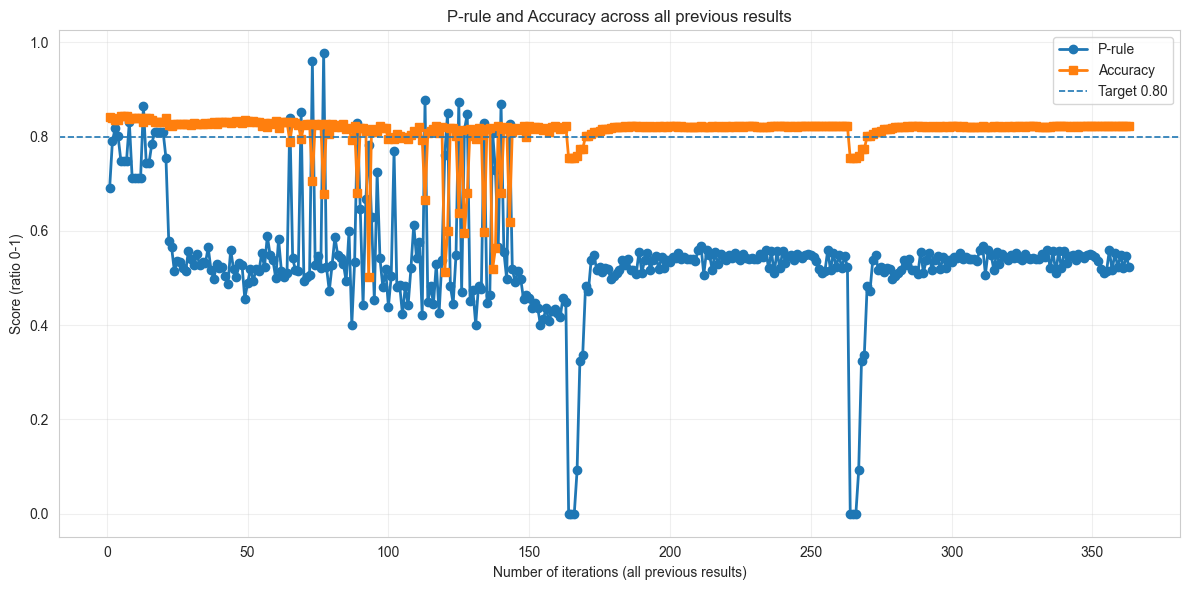

In [2]:
# Courbe globale: Accuracy et P-rule sur toutes les executions precedentes
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def _to_ratio(value):
    """Convertit en ratio [0,1] si la valeur est en pourcentage."""
    if value is None:
        return None
    value = float(value)
    return value / 100.0 if value > 1.0 else value


def _extract_min_prule_from_metrics(metrics: dict):
    prule_keys = [k for k in metrics.keys() if k.startswith("p_rule_")]
    if not prule_keys:
        return None
    return min(float(metrics[k]) for k in prule_keys)


def _parse_generic_records(records, source_name):
    rows = []
    for idx, rec in enumerate(records, start=1):
        timestamp = rec.get("timestamp")

        # Cas 1: format notebook/orchestrator_memory avec final_metrics
        if isinstance(rec, dict) and "final_metrics" in rec:
            fm = rec.get("final_metrics", {})
            acc = fm.get("acc")
            if acc is None:
                acc = rec.get("auroc_final")  # fallback rare
            min_prule = rec.get("min_prule_final")
            if min_prule is None:
                min_prule = _extract_min_prule_from_metrics(fm)

            rows.append({
                "source": source_name,
                "iteration": int(idx),
                "accuracy": _to_ratio(acc),
                "p_rule": _to_ratio(min_prule),
                "timestamp": timestamp,
            })
            continue

        # Cas 2: format llm_orchestrator_memory / training_metrics_enhanced
        if isinstance(rec, dict):
            step = rec.get("step", idx)
            acc = rec.get("accuracy")
            min_prule = rec.get("min_p_rule")
            if min_prule is None and isinstance(rec.get("p_rules"), dict) and rec["p_rules"]:
                min_prule = min(float(v) for v in rec["p_rules"].values())

            rows.append({
                "source": source_name,
                "iteration": int(step),
                "accuracy": _to_ratio(acc),
                "p_rule": _to_ratio(min_prule),
                "timestamp": timestamp,
            })

    return rows


def load_all_previous_results(base_dir: Path):
    json_files = [
        "orchestrator_memory.json",
        "orchestrator_enhanced_memory.json",
        "llm_orchestrator_memory.json",
        "demo_memory.json",
        "test_memory.json",
        "training_metrics_enhanced.json",
    ]

    all_rows = []
    for fname in json_files:
        fpath = base_dir / fname
        if not fpath.exists():
            continue
        try:
            with open(fpath, "r", encoding="utf-8") as f:
                data = json.load(f)
            if isinstance(data, list):
                all_rows.extend(_parse_generic_records(data, fname))
            else:
                print(f"[INFO] {fname}: format ignore (attendu: liste)")
        except Exception as e:
            print(f"[WARN] Impossible de lire {fname}: {e}")

    if not all_rows:
        return pd.DataFrame(columns=["source", "iteration", "accuracy", "p_rule", "timestamp"])

    df = pd.DataFrame(all_rows)
    df = df.dropna(subset=["accuracy", "p_rule"])
    if df.empty:
        return df

    # Tri chronologique si timestamp disponible, sinon par source+iteration
    if "timestamp" in df.columns and df["timestamp"].notna().any():
        df["ts_sort"] = pd.to_datetime(df["timestamp"], errors="coerce")
        df = df.sort_values(["ts_sort", "source", "iteration"], kind="stable")
    else:
        df = df.sort_values(["source", "iteration"], kind="stable")

    # Axe X global: 1..N (nombre total d'iterations observees)
    df = df.reset_index(drop=True)
    df["global_iteration"] = np.arange(1, len(df) + 1)
    return df


base_dir = Path(".")
df_hist = load_all_previous_results(base_dir)

if df_hist.empty:
    print("Aucune metrique exploitable trouvee dans les fichiers JSON.")
else:
    print(f"{len(df_hist)} points charges depuis: {', '.join(sorted(df_hist['source'].unique()))}")
    print(df_hist[["source", "iteration", "accuracy", "p_rule"]].tail(10))

    plt.figure(figsize=(12, 6))
    plt.plot(df_hist["global_iteration"], df_hist["p_rule"], marker="o", linewidth=2, label="P-rule")
    plt.plot(df_hist["global_iteration"], df_hist["accuracy"], marker="s", linewidth=2, label="Accuracy")

    plt.axhline(0.80, linestyle="--", linewidth=1.2, label="Target 0.80")
    plt.xlabel("Number of iterations (all previous results)")
    plt.ylabel("Score (ratio 0-1)")
    plt.title("P-rule and Accuracy across all previous results")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()